✅ Loaded best checkpoint from epoch 8

🎯 Selected confident error: ISIC_0025209
   True class: bkl | Predicted: akiec (Conf: 0.96)

🔍 Running LIME...


  0%|          | 0/1000 [00:00<?, ?it/s]

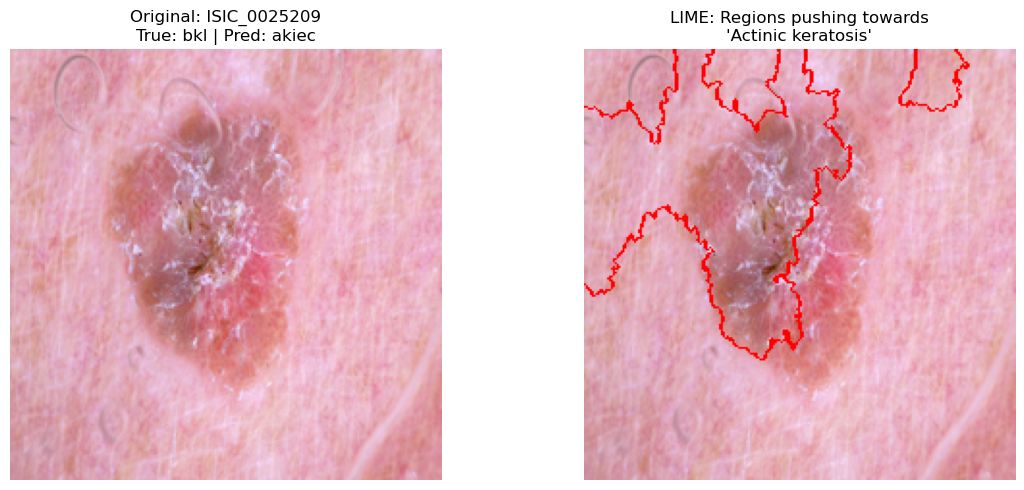


🔍 Running SHAP...
✅ Confirmed original_image shape: (224, 224, 3)


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [01:01, 61.18s/it]               



🎨 Generating manual SHAP plots...
✅ Dropped batch. Shape: (224, 224, 3, 7)
✅ Aggregated RGB channels. Shape: (224, 224, 7)


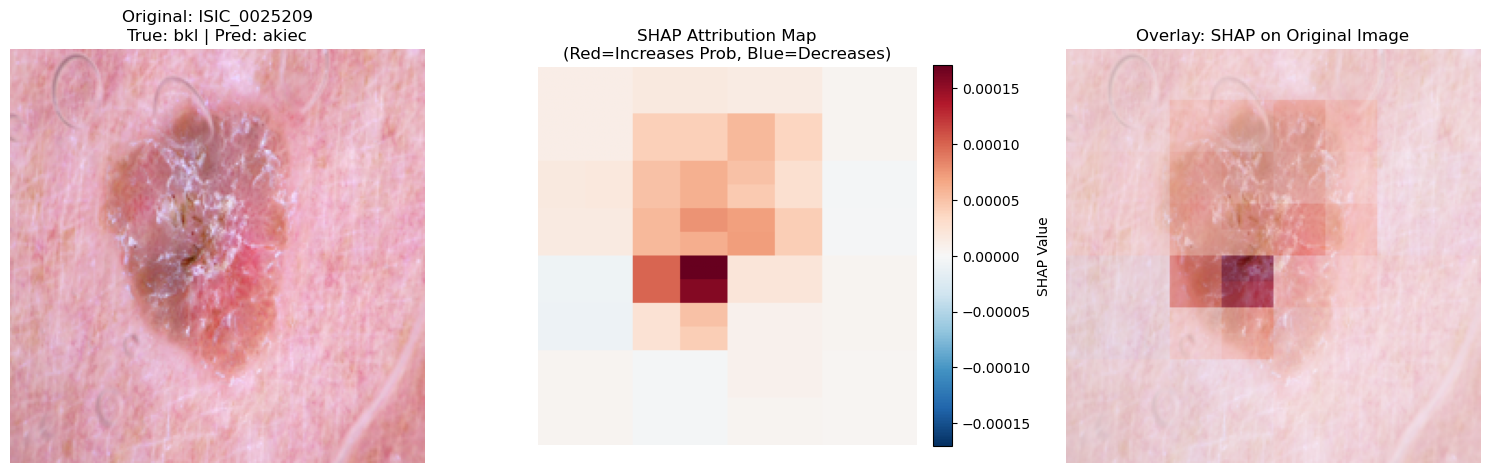

In [1]:
import torch
import torchvision.transforms as transforms
import torchvision.models as models
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime import lime_image
from skimage.segmentation import mark_boundaries
from pathlib import Path

# =========================================================================
# 1. SETUP 
# =========================================================================
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CLASS_NAMES = {
    "akiec": "Actinic keratosis", "bcc": "Basal cell carcinoma", 
    "bkl": "Benign keratosis", "df": "Dermatofibroma", 
    "mel": "Melanoma", "nv": "Melanocytic nevus", "vasc": "Vascular lesion"
}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
IMG_SIZE = 224
DEVICE="cpu"
# Paths (Adjust OUT_DIR if your files are elsewhere)
OUT_DIR = Path(r"C:\Users\siria\Downloads\VisAI")
pred_all = pd.read_csv(OUT_DIR / "predictions_all.csv")

# =========================================================================
# 2. LOAD MODEL 
# =========================================================================
def build_model():
    m = models.resnet50(weights=None)
    m.fc = torch.nn.Linear(m.fc.in_features, len(CLASSES))
    return m

model = build_model()
state = torch.load(OUT_DIR / "best.pt", map_location="cpu")
model.load_state_dict(state["model"]) # This fixes the state_dict error!
model.eval()
print(f"✅ Loaded best checkpoint from epoch {state['epoch']}")

EVAL_TF = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), 
    transforms.Normalize(MEAN, STD)
])

# =========================================================================
# 3. STRICT BLACK-BOX PREDICTION FUNCTION
# =========================================================================
@torch.no_grad()
def black_box_predict(images):
    """
    Strict black-box wrapper. 
    Input: Numpy array of shape (N, H, W, C) or (H, W, C) with uint8 values.
    Output: Numpy array of shape (N, 7) with softmax probabilities.
    """
    # Handle single image vs batch
    if isinstance(images, np.ndarray) and images.ndim == 3:
        images = [images]
    
    out = []
    for im in images:
        # FIX: Convert numpy array to PIL Image before applying torchvision transforms
        pil_img = Image.fromarray(np.uint8(im))
        
        # Apply transforms, add batch dimension, and move to device
        x = EVAL_TF(pil_img).unsqueeze(0).to(DEVICE)
        
        # Get softmax probabilities
        probs = torch.softmax(model(x).float(), 1).cpu().numpy()
        out.append(probs[0])
        
    return np.array(out)

# =========================================================================
# 4. SELECT AN INTERESTING IMAGE (Targeting H1: Confident Errors)
# =========================================================================
# Filter for test set
test = pred_all[pred_all['split'] == 'test'].reset_index(drop=True)

# Let's find a "Most confident error" as suggested in Section 2 of the notebook
# (Model is >90% confident, but completely wrong)
confident_errors = test[(~test['correct']) & (test['confidence'] > 0.90)]

if len(confident_errors) > 0:
    target_row = confident_errors.iloc[0]
    print(f"\n🎯 Selected confident error: {target_row['image_id']}")
    print(f"   True class: {target_row['dx']} | Predicted: {target_row['pred_dx']} (Conf: {target_row['confidence']:.2f})")
else:
    target_row = test.iloc[0]
    print("\n⚠️ No confident errors found, using first test image.")

# Load the image (Assuming images are in a 'dataset' folder inside OUT_DIR)
img_path = OUT_DIR / "dataset" / f"{target_row['image_id']}.jpg"
original_image = np.array(Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))

# =========================================================================
# 5. APPLY LIME (Local Interpretable Model-agnostic Explanations)
# =========================================================================
print("\n🔍 Running LIME...")
lime_explainer = lime_image.LimeImageExplainer(verbose=False)
lime_explanation = lime_explainer.explain_instance(
    original_image, 
    black_box_predict, 
    top_labels=3,       
    hide_color=0,       
    num_samples=1000    
)

# Get the index of the predicted class for visualization
pred_class_idx = CLASSES.index(target_row['pred_dx'])
temp, mask = lime_explanation.get_image_and_mask(
    pred_class_idx, 
    positive_only=True, 
    num_features=10,    
    hide_rest=False     
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.imshow(original_image)
ax1.set_title(f"Original: {target_row['image_id']}\nTrue: {target_row['dx']} | Pred: {target_row['pred_dx']}")
ax1.axis('off')

ax2.imshow(mark_boundaries(temp, mask, color=(1, 0, 0))) 
ax2.set_title(f"LIME: Regions pushing towards\n'{CLASS_NAMES[target_row['pred_dx']]}'")
ax2.axis('off')
plt.tight_layout()
plt.show()

# =========================================================================
# 6. APPLY SHAP (Bulletproof Shape Enforcement)
# =========================================================================
print("\n🔍 Running SHAP...")

# 1. FORCE original_image to be exactly (224, 224, 3)
if original_image.shape != (IMG_SIZE, IMG_SIZE, 3):
    print(f"⚠️ original_image had shape {original_image.shape}. Forcing resize to ({IMG_SIZE}, {IMG_SIZE}, 3)...")
    # If it's a 2D grayscale or corrupted, convert back to RGB and resize
    if original_image.ndim == 2:
        original_image = np.stack([original_image]*3, axis=-1)
    original_image = np.array(Image.fromarray(np.uint8(original_image)).resize((IMG_SIZE, IMG_SIZE)))

print(f"✅ Confirmed original_image shape: {original_image.shape}")

# 2. Create Masker and Explainer
masker = shap.maskers.Image("blur(64,64)", original_image.shape)
shap_explainer = shap.Explainer(
    black_box_predict, 
    masker, 
    output_names=CLASSES 
)

# 3. Pass a strict batch of 1 image: shape (1, 224, 224, 3)
shap_input = np.expand_dims(original_image, 0) 
shap_values = shap_explainer(shap_input, max_evals=500)

import matplotlib.pyplot as plt
import numpy as np

# =========================================================================
# 7. MANUAL SHAP VISUALIZATION (Bulletproof 5D to 2D Extraction)
# =========================================================================
print("\n🎨 Generating manual SHAP plots...")

# 1. Get the raw SHAP values array and drop the batch dimension
raw_vals = shap_values.values[0]  # Shape is now (224, 224, 3, 7)
print(f"✅ Dropped batch. Shape: {raw_vals.shape}")

# 2. Aggregate the 3 color channels (RGB) into a single importance score per pixel
# Summing across axis=2 gives the total SHAP value for each pixel location
spatial_vals = raw_vals.sum(axis=2)  # Shape is now (224, 224, 7)
print(f"✅ Aggregated RGB channels. Shape: {spatial_vals.shape}")

# 3. Select ONLY the slice for the predicted class -> Guarantees (224, 224)
class_shap_values = spatial_vals[:, :, pred_class_idx]

# 4. Calculate symmetric max value for the color scale
v_max = np.max(np.abs(class_shap_values))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Original Image
axes[0].imshow(original_image)
axes[0].set_title(f"Original: {target_row['image_id']}\nTrue: {target_row['dx']} | Pred: {target_row['pred_dx']}")
axes[0].axis('off')

# Plot 2: SHAP Attribution Map (Heatmap)
im = axes[1].imshow(class_shap_values, cmap='RdBu_r', vmin=-v_max, vmax=v_max)
axes[1].set_title("SHAP Attribution Map\n(Red=Increases Prob, Blue=Decreases)")
axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label='SHAP Value')

# Plot 3: Overlay on Original Image
axes[2].imshow(original_image)
axes[2].imshow(class_shap_values, cmap='RdBu_r', alpha=0.5, vmin=-v_max, vmax=v_max)
axes[2].set_title("Overlay: SHAP on Original Image")
axes[2].axis('off')

plt.tight_layout()
plt.show()

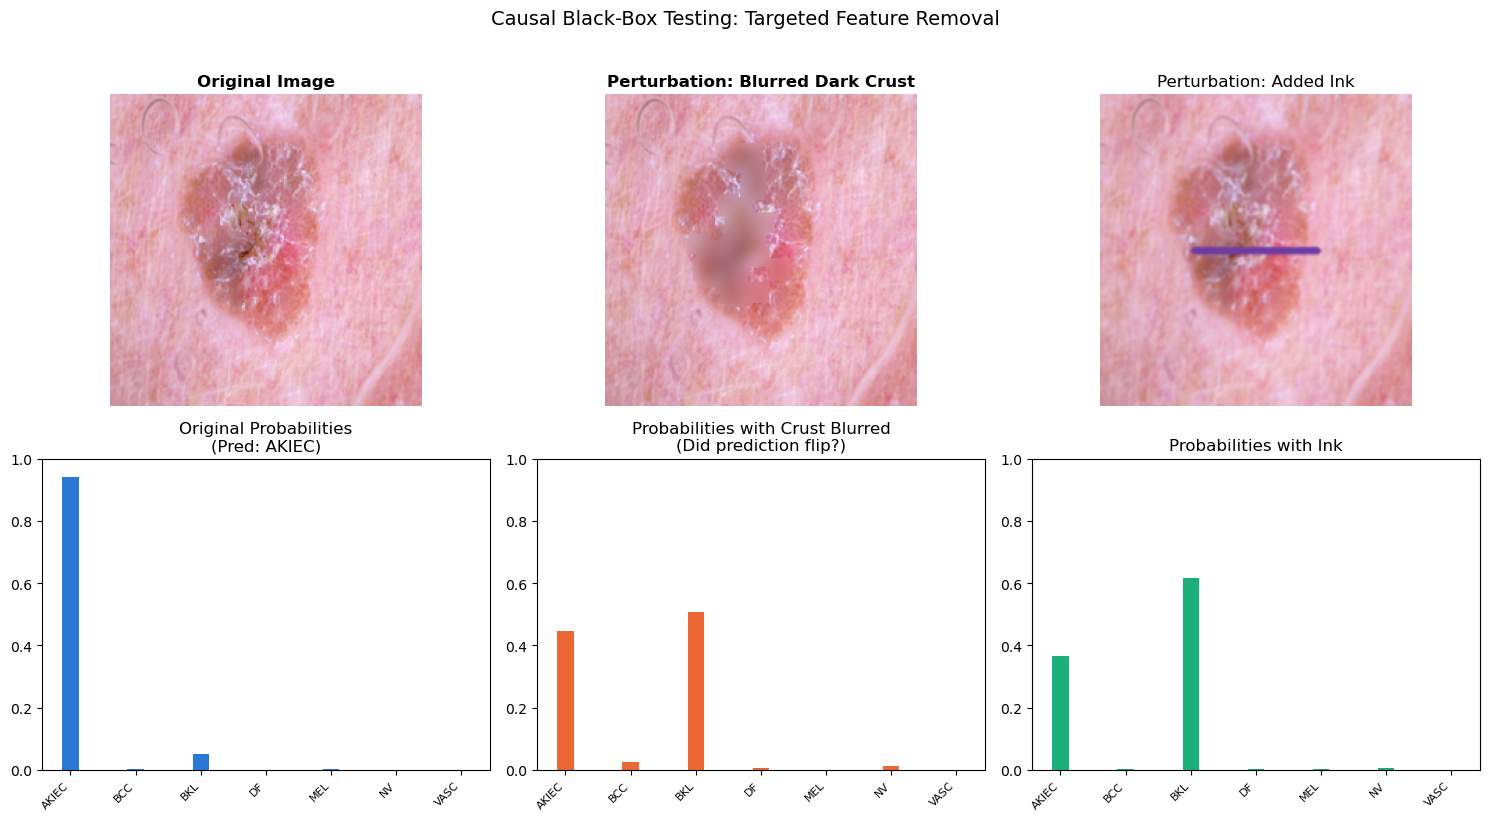

In [10]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import torch
import torchvision.transforms as transforms
import torchvision.models as models

# =========================================================================
# 1. REUSE SETUP & BLACK-BOX WRAPPER
# =========================================================================
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
IMG_SIZE = 224
DEVICE = "cpu"

OUT_DIR = Path(r"C:\Users\siria\Downloads\VisAI")
pred_all = pd.read_csv(OUT_DIR / "predictions_all.csv")

def build_model():
    m = models.resnet50(weights=None)
    m.fc = torch.nn.Linear(m.fc.in_features, len(CLASSES))
    return m

model = build_model()
state = torch.load(OUT_DIR / "best.pt", map_location="cpu")
model.load_state_dict(state["model"])
model.eval()

EVAL_TF = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), 
    transforms.Normalize(MEAN, STD)
])

@torch.no_grad()
def black_box_predict(images):
    if isinstance(images, np.ndarray) and images.ndim == 3:
        images = [images]
    out = []
    for im in images:
        pil_img = Image.fromarray(np.uint8(im))
        x = EVAL_TF(pil_img).unsqueeze(0).to(DEVICE)
        probs = torch.softmax(model(x).float(), 1).cpu().numpy()
        out.append(probs[0])
    return np.array(out)

# Target Image
target_id = "ISIC_0025209"
target_img = np.array(Image.open(OUT_DIR / "dataset" / f"{target_id}.jpg").convert("RGB").resize((IMG_SIZE, IMG_SIZE)))

# =========================================================================
# 2. TARGETED PERTURBATION: BLUR ONLY THE DARK CRUST
# =========================================================================
def blur_dark_crust(img, percentile=5):
    """
    Finds the darkest pixels in the image and blurs ONLY those pixels.
    This targets the specific "dark crust" texture without destroying the whole lesion.
    """
    out = img.copy()
    gray = cv2.cvtColor(out, cv2.COLOR_RGB2GRAY)
    
    # Find the threshold for the darkest X% of pixels
    threshold = np.percentile(gray, percentile)
    
    # Create a mask of the dark pixels
    mask = (gray <= threshold).astype(np.uint8) * 255
    
    # Dilate the mask slightly to blur the edges of the crust too
    kernel = np.ones((15, 15), np.uint8)
    mask_dilated = cv2.dilate(mask, kernel, iterations=1)
    
    # Apply a heavy Gaussian blur to the whole image
    blurred_img = cv2.GaussianBlur(out, (31, 31), 0)
    
    # Use the mask to copy ONLY the blurred dark pixels back onto the original image
    out[mask_dilated > 0] = blurred_img[mask_dilated > 0]
    return out

# Generate the targeted perturbation
img_targeted_blur = blur_dark_crust(target_img, percentile=0.7)

# Query black-box
probs_orig = black_box_predict(target_img)[0]
probs_targeted = black_box_predict(img_targeted_blur)[0]

# =========================================================================
# 3. VISUALIZE THE CAUSAL TEST
# =========================================================================
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Top row: Images
axes[0, 0].imshow(target_img)
axes[0, 0].set_title("Original Image", fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(img_targeted_blur)
axes[0, 1].set_title("Perturbation: Blurred Dark Crust", fontweight='bold')
axes[0, 1].axis('off')

# Add a synthetic ink image for comparison (from previous step)
def add_synthetic_ink(img):
    out = img.copy()
    h, w = out.shape[:2]
    cv2.line(out, (int(w*0.3), int(h*0.5)), (int(w*0.7), int(h*0.5)), (110, 60, 160), 4, cv2.LINE_AA)
    return cv2.GaussianBlur(out, (3, 3), 0)

img_ink = add_synthetic_ink(target_img)
probs_ink = black_box_predict(img_ink)[0]
axes[0, 2].imshow(img_ink)
axes[0, 2].set_title("Perturbation: Added Ink")
axes[0, 2].axis('off')

# Bottom row: Probability Bar Charts
classes_short = [c.upper() for c in CLASSES]
x = np.arange(len(CLASSES))
width = 0.25

# Original
axes[1, 0].bar(x, probs_orig, width, color='#2a78d6')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(classes_short, rotation=45, ha='right', fontsize=8)
axes[1, 0].set_ylim(0, 1)
axes[1, 0].set_title("Original Probabilities\n(Pred: AKIEC)")

# Targeted Blur
axes[1, 1].bar(x, probs_targeted, width, color='#eb6834')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(classes_short, rotation=45, ha='right', fontsize=8)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_title("Probabilities with Crust Blurred\n(Did prediction flip?)")

# Ink
axes[1, 2].bar(x, probs_ink, width, color='#1baf7a')
axes[1, 2].set_xticks(x)
axes[1, 2].set_xticklabels(classes_short, rotation=45, ha='right', fontsize=8)
axes[1, 2].set_ylim(0, 1)
axes[1, 2].set_title("Probabilities with Ink")

plt.suptitle("Causal Black-Box Testing: Targeted Feature Removal", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Analyzing 1502 test images across 4 labs.

BALANCED ACCURACY BY LAB ORIGIN

Accuracy vs. Balanced Accuracy by Lab:
         dataset  balanced_accuracy  overall_accuracy  imbalance_gap
1   vidir_modern              0.775             0.763         -0.012
2  vidir_molemax              0.622             0.970          0.348
0      rosendahl              0.504             0.648          0.145
3    vienna_dias              0.383             0.818          0.435

CLUSTERING LABS BY PIXEL FEATURES (UMAP)
Extracting pixel features for UMAP clustering...
Running UMAP dimensionality reduction on pixel features...


c:\Users\siria\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\siria\AppData\Local\Temp\ipykernel_41680\3805338189.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


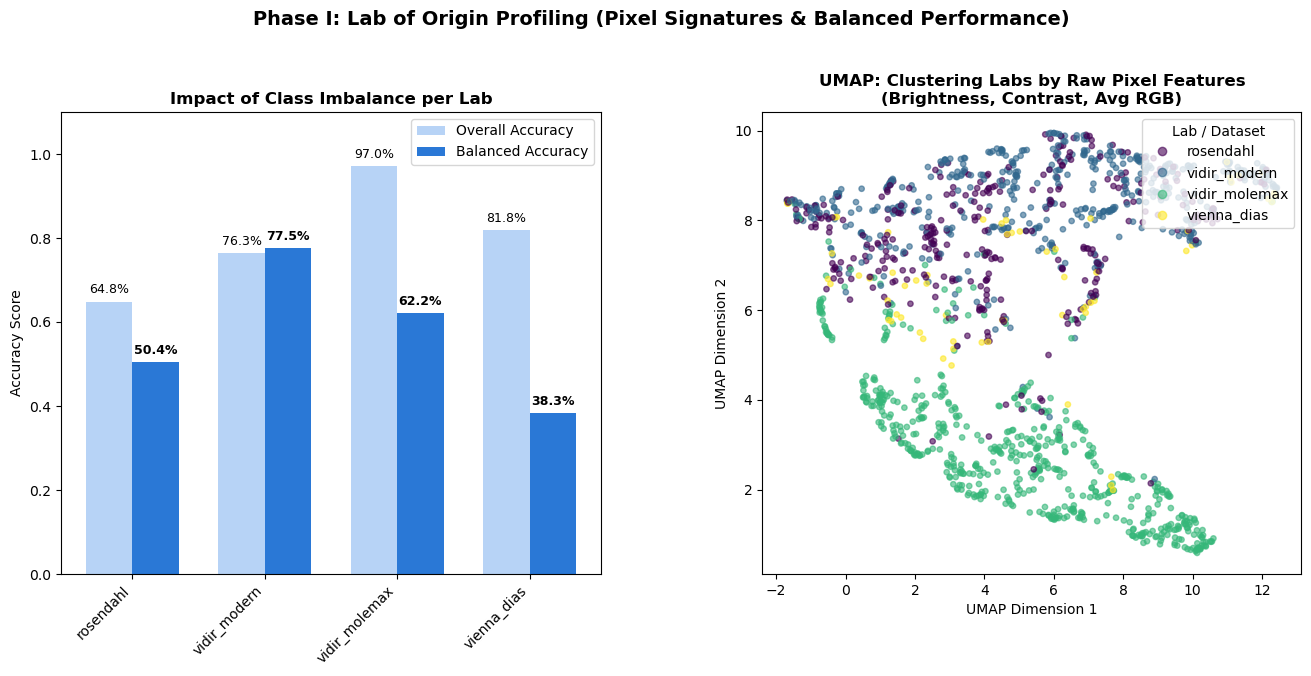


PER-CLASS ACCURACY HEATMAP (Why is Balanced Accuracy low?)


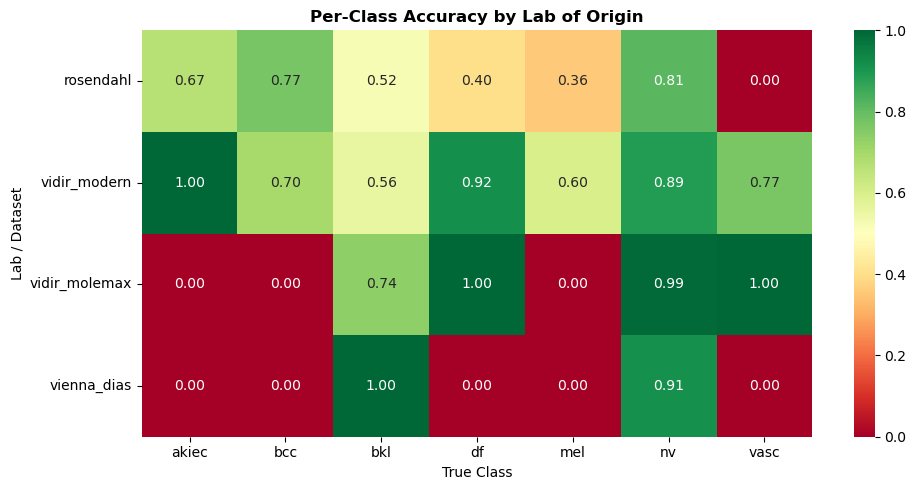

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import umap # Included in your notebook's pip install list

# =========================================================================
# 1. SETUP & LOAD DATA
# =========================================================================
OUT_DIR = Path(r"C:\Users\siria\Downloads\VisAI")
metadata = pd.read_csv(OUT_DIR / "dataset" / "HAM10000_metadata")
pred_all = pd.read_csv(OUT_DIR / "predictions_all.csv")

CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

# Merge and filter for test set
test_with_meta = pred_all[pred_all['split'] == 'test'].merge(
    metadata[['image_id', 'dx', 'dataset']], 
    on='image_id', 
    how='left'
)

# Drop rows where dataset (lab) is unknown
test_labs = test_with_meta.dropna(subset=['dataset']).copy()
print(f"Analyzing {len(test_labs)} test images across {test_labs['dataset'].nunique()} labs.")

# =========================================================================
# 2. BALANCED ACCURACY BY LAB (Handling Imbalance)
# =========================================================================
print("\n" + "="*70)
print("BALANCED ACCURACY BY LAB ORIGIN")
print("="*70)

# Step A: Calculate per-class accuracy (Recall) for each lab
class_acc = test_labs.groupby(['dataset', 'dx_x'])['correct'].mean().reset_index()

# Step B: Calculate Balanced Accuracy (mean of per-class accuracies) per lab
balanced_acc = class_acc.groupby('dataset')['correct'].mean().reset_index(name='balanced_accuracy')

# Step C: Calculate Overall Accuracy per lab (for comparison)
overall_acc = test_labs.groupby('dataset')['correct'].mean().reset_index(name='overall_accuracy')

# Step D: Merge them
lab_metrics = pd.merge(balanced_acc, overall_acc, on='dataset')
lab_metrics['imbalance_gap'] = lab_metrics['overall_accuracy'] - lab_metrics['balanced_accuracy']

print("\nAccuracy vs. Balanced Accuracy by Lab:")
print(lab_metrics.round(3).sort_values('balanced_accuracy', ascending=False))

# =========================================================================
# 3. PIXEL-BASED LAB CLUSTERING (UMAP on Image Features)
# =========================================================================
print("\n" + "="*70)
print("CLUSTERING LABS BY PIXEL FEATURES (UMAP)")
print("="*70)

# We use the model-agnostic pixel features computed in Section 3 of your notebook.
# If you haven't run Section 3 yet, this block computes them quickly for the test set.
import cv2
import time

def get_quick_pixel_features(image_id):
    try:
        # Load image (assuming load_image function from your notebook is available, 
        # otherwise we use a fallback path)
        img_path = OUT_DIR / "dataset" / f"{image_id}.jpg"
        if not img_path.exists(): return None
        img = np.array(Image.open(img_path).convert("RGB").resize((224, 224)))
        
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
        brightness = float(gray.mean() / 255.0)
        contrast = float(gray.std() / 255.0)
        
        # Color features (average R, G, B)
        avg_r, avg_g, avg_b = img.mean(axis=(0, 1)) / 255.0
        
        return [brightness, contrast, avg_r, avg_g, avg_b]
    except:
        return None

print("Extracting pixel features for UMAP clustering...")
features = []
valid_indices = []
for idx, row in test_labs.iterrows():
    feats = get_quick_pixel_features(row['image_id'])
    if feats:
        features.append(feats)
        valid_indices.append(idx)

# Create a dataframe of features for the valid images
features_df = pd.DataFrame(features, index=valid_indices, columns=['brightness', 'contrast', 'avg_r', 'avg_g', 'avg_b'])

# Apply UMAP to reduce these 5 pixel features to 2D
print("Running UMAP dimensionality reduction on pixel features...")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embedding = reducer.fit_transform(features_df)

# Add UMAP coordinates back to the main dataframe
test_labs['umap_x'] = np.nan
test_labs['umap_y'] = np.nan
test_labs.loc[valid_indices, 'umap_x'] = embedding[:, 0]
test_labs.loc[valid_indices, 'umap_y'] = embedding[:, 1]

# =========================================================================
# 4. VISUALIZATION
# =========================================================================
fig = plt.figure(figsize=(16, 6))
gs = fig.add_gridspec(1, 2, wspace=0.3)

# --- Plot 1: Overall Accuracy vs. Balanced Accuracy ---
ax1 = fig.add_subplot(gs[0, 0])
x = np.arange(len(lab_metrics))
width = 0.35
bars1 = ax1.bar(x - width/2, lab_metrics['overall_accuracy'], width, label='Overall Accuracy', color='#b7d3f6')
bars2 = ax1.bar(x + width/2, lab_metrics['balanced_accuracy'], width, label='Balanced Accuracy', color='#2a78d6')

ax1.set_xticks(x)
ax1.set_xticklabels(lab_metrics['dataset'], rotation=45, ha='right')
ax1.set_ylabel('Accuracy Score')
ax1.set_title('Impact of Class Imbalance per Lab', fontweight='bold')
ax1.legend()
ax1.set_ylim(0, 1.1)

# Add text labels
for i in range(len(lab_metrics)):
    ax1.text(i - width/2, lab_metrics.iloc[i]['overall_accuracy'] + 0.02, f"{lab_metrics.iloc[i]['overall_accuracy']:.1%}", ha='center', fontsize=9)
    ax1.text(i + width/2, lab_metrics.iloc[i]['balanced_accuracy'] + 0.02, f"{lab_metrics.iloc[i]['balanced_accuracy']:.1%}", ha='center', fontsize=9, fontweight='bold')

# --- Plot 2: UMAP Clustering of Labs by Pixel Features ---
ax2 = fig.add_subplot(gs[0, 1])
scatter = ax2.scatter(
    test_labs['umap_x'], 
    test_labs['umap_y'], 
    c=test_labs['dataset'].astype('category').cat.codes, 
    cmap='viridis', 
    alpha=0.6, 
    s=15
)

# Create a legend for the datasets
handles, _ = scatter.legend_elements()
labels = test_labs['dataset'].astype('category').cat.categories
ax2.legend(handles, labels, title="Lab / Dataset", loc="upper right")

ax2.set_title("UMAP: Clustering Labs by Raw Pixel Features\n(Brightness, Contrast, Avg RGB)", fontweight='bold')
ax2.set_xlabel("UMAP Dimension 1")
ax2.set_ylabel("UMAP Dimension 2")

plt.suptitle("Phase I: Lab of Origin Profiling (Pixel Signatures & Balanced Performance)", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

# =========================================================================
# 5. PER-CLASS ACCURACY HEATMAP (To explain the Balanced Accuracy)
# =========================================================================
print("\n" + "="*70)
print("PER-CLASS ACCURACY HEATMAP (Why is Balanced Accuracy low?)")
print("="*70)

# Pivot table: rows = dataset, columns = true class (dx), values = accuracy
heatmap_data = class_acc.pivot(index='dataset', columns='dx_x', values='correct').fillna(0)

plt.figure(figsize=(10, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Per-Class Accuracy by Lab of Origin", fontweight='bold', fontsize=12)
plt.ylabel("Lab / Dataset")
plt.xlabel("True Class")
plt.tight_layout()
plt.show()